# copaings demo: from an LSST catalog to the blending-entropy curve

This notebook runs the whole `copaings` pipeline, one stage per cell, on a small piece of sky (~0.07 deg²), and ends with the
curve *fraction of LSST objects with S_b > 0.2 vs i magnitude* for Euclid and HST. On the full 14-tract runs the same stages are
submitted as slurm jobs (last section).

| stage | what it does | output (under `<out_root>/<name>/`) |
|---|---|---|
| `prep` | loads LSST (butler), Euclid Q1 and HST catalogs, cuts, footprints | `catalogs/{lsst,euclid,hst}.parquet`, `meta.json` |
| `fof` | friends-of-friends matching true catalog ↔ LSST | `groups/{E,H}_fof.pkl` |
| `eot` | ellipse overlap test: splits each FoF group into groups of really overlapping ellipses | `groups/{E,H}_eot_part_*.pkl` |
| `eot_merge` | merges the EOT parts | `groups/{E,H}_no_overlap.pkl` |
| `magfit` | predicts the Euclid VIS / HST F814 magnitude of every LSST object (tree on ugrizy + size) | `catalogs/lsst_fit.parquet`, `fit_params.json` |
| `sb` | blending entropy S_b per group | `sb/*_part_*.parquet` |
| `sb_merge` | assembles S_b / purity for all LSST objects | `lsst_sb.parquet` |
| `plots` | standard figures | `plots/*.pdf` |

Needs: the `friendly` package (set `FRIENDLY_PATH`, see README), a butler with the DP2 `object` table (only for `prep`), and the Euclid Q1 / HST catalogs.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))          # use this checkout without installing it
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from copaings.config import Case
from copaings import cli, stages, plots

## 1. Define the case

A *case* is a small configuration (a yaml file in `cases/`, or a `Case` object built in code, as here). Everything it does not set has a default,
see `copaings/config.py`. The case `name` fixes the output directory, so change it for every variation you want to keep.

In [2]:
case = Case(
    name='demo_dp2_box',
    out_root='./copaings_runs',
    # LSST catalog (butler)
    repo='dp2_prep',
    collections='LSSTCam/runs/DRP/DP2/v30_0_8/DM-55060/stage3',
    skymap='lsst_cells_v2',
    dataset_type='object',
    tracts=[5063],
    sky_box=[53.00, 53.30, -27.95, -27.70],   # [ra_min, ra_max, dec_min, dec_max]: a tiny box inside the HST field
    # matching
    linking_length=3.0,                        # arcsec, FoF
    mag_cut=35,
    euclid_region='auto',                      # every Euclid tile that has a file and holds LSST objects
    eot_dense_max=0,                           # always use the KD-tree ellipse overlap test
    # parallelism (here everything runs serially in the notebook)
    n_eot_tasks=4,
    n_sb_tasks=4,
)
# the same case from a yaml file:  Case.from_yaml('../cases/demo_dp2_box.yaml')
print('outputs go to', case.out_dir)

outputs go to ./copaings_runs/demo_dp2_box


## 2. `prep`: build the catalogs

Reads the butler `object` table (only the needed columns), the Euclid MER tiles and the HST catalog, applies the magnitude cut and computes footprints and covered areas.
Group indices used later are *row positions* in these three tables, so every later stage must read exactly these files.

In [3]:
cli.run_stage(case, 'prep')
meta = json.load(open(case.path('catalogs', 'meta.json')))
pd.DataFrame({'objects after cuts': meta['n_after_cut'], 'covered area [deg2]': meta['area_deg2']})

Added tract 5063: 724,132 rows, 21 columns
Euclid: reading 1 tiles [35935]


{
  "n_raw": {
    "LSST": 14045,
    "Euclid": 23932,
    "HST": 98356
  },
  "area_hull_deg2": {
    "LSST": 0.0748967521120408,
    "Euclid": 0.07492484281435223,
    "HST": 0.0749787351434567
  },
  "area_deg2": {
    "LSST": 0.0728,
    "Euclid": 0.0728,
    "HST": 0.0728
  },
  "n_after_cut": {
    "LSST": 14044,
    "Euclid": 23464,
    "HST": 84076
  }
}


,objects after cuts,covered area [deg2]
LSST,14044,0.0728
Euclid,23464,0.0728
HST,84076,0.0728


## 3. `fof`: friends-of-friends matching

One job per survey. Keeps only groups that contain at least one true object and one LSST object.

In [4]:
for tel in ['Euclid', 'HST']:
    cli.run_stage(case, 'fof', tel)
    print(tel, json.load(open(case.path('groups', f'{tel[0]}_fof_stats.json'))))

Euclid: {'n_groups': 10451, 'n_multi_tract_groups': 0, 'common_frame_xy': True}
Euclid {'n_groups': 10451, 'n_multi_tract_groups': 0, 'common_frame_xy': True}


HST: {'n_groups': 6228, 'n_multi_tract_groups': 0, 'common_frame_xy': True}
HST {'n_groups': 6228, 'n_multi_tract_groups': 0, 'common_frame_xy': True}


## 4. `eot` and `eot_merge`: ellipse overlap test

Each FoF group is split into connected components of *really overlapping* ellipses (LSST ellipses from the second moments, true-catalog ellipses from their sizes convolved with the PSF).
On the cluster this is a slurm array (`--task-id`); here `run_all=True` runs all slices one after the other.

In [5]:
for tel in ['Euclid', 'HST']:
    cli.run_stage(case, 'eot', tel, run_all=True)
    cli.run_stage(case, 'eot_merge', tel)

Euclid: 12,531 no-overlap groups


HST: 13,265 no-overlap groups


In [6]:
# groups are [true_indices, lsst_indices]; the (n_true, n_lsst) counts are what the "unrecognized blend" analysis uses
for tel in ['Euclid', 'HST']:
    groups = stages.load_groups(case, tel)
    nt = np.array([len(g[0]) for g in groups]); no = np.array([len(g[1]) for g in groups])
    print(f'{tel}: {len(groups):,} groups | 1-1: {np.mean((nt == 1) & (no == 1)):.0%} | '
          f'more true than LSST objects (unrecognized blends): {np.mean(nt > no):.1%}')

Euclid: 12,531 groups | 1-1: 87% | more true than LSST objects (unrecognized blends): 11.4%
HST: 13,265 groups | 1-1: 56% | more true than LSST objects (unrecognized blends): 43.2%


## 5. `magfit`: magnitudes of the LSST objects in the Euclid and HST bands

S_b needs the magnitude difference between each LSST object and each overlapping true galaxy, so the LSST objects are put in the VIS / F814 bands.
A gradient-boosted tree trained on the 1-1 groups predicts VIS (Euclid) and F814 (HST) from the LSST ugrizy colours and size information (observed size, PSF size, ellipticity). Missing bands are handled natively by the trees.

In [7]:
cli.run_stage(case, 'magfit')
fit = json.load(open(case.path('catalogs', 'fit_params.json')))
print('features used:', fit['tree_features_used'])
pd.DataFrame(fit['tree_metrics']).T[['n_train', 'n_test', 'bias', 'mad_scatter', 'frac_abs_gt_1']]   # held-out sky blocks

Euclid {'n_train': 8234, 'n_test': 2702, 'bias': 0.03370503215648846, 'mad_scatter': 0.17300339371218426, 'std': 0.3039848331018261, 'frac_abs_gt_1': 0.013323464100666173}


HST {'n_train': 5563, 'n_test': 1908, 'bias': 0.008944540241026644, 'mad_scatter': 0.16969781864167177, 'std': 0.31769995074570834, 'frac_abs_gt_1': 0.012054507337526206}


features used: {'Euclid': ['i_mag', 'u-i', 'g-i', 'r-i', 'z-i', 'y-i', 'size_arcsec', 'psf_sigma_arcsec', 'size_over_psf', 'ellipticity'], 'HST': ['i_mag', 'u-i', 'g-i', 'r-i', 'z-i', 'y-i', 'size_arcsec', 'psf_sigma_arcsec', 'size_over_psf', 'ellipticity']}


,n_train,n_test,bias,mad_scatter,frac_abs_gt_1
Euclid,8234.0,2702.0,0.033705,0.173003,0.013323
HST,5563.0,1908.0,0.008945,0.169698,0.012055


## 6. `sb` and `sb_merge`: blending entropy

`sb` computes S_b for every LSST object in a group that is not 1-1 (array job, `run_all=True` here). `sb_merge` then fills the conventions:

* **S_b ≥ 0**: computed entropy (0 = unambiguous, larger = the LSST object overlaps several galaxies of comparable weight)
* **S_b = 0**: the object is in a 1-1 group after the overlap test (a single candidate)
* **S_b = −1**: the object overlaps no galaxy of that survey at all (outside the survey, no neighbour, or no ellipse overlap)
* **NaN**: only if something failed (a warning is printed and the count is saved in `sb/sb_merge_stats.json`)

In [8]:
for tel in ['Euclid', 'HST']:
    cli.run_stage(case, 'sb', tel, run_all=True)
cli.run_stage(case, 'sb_merge')

{
  "Euclid": {
    "n_objects": 14044,
    "n_one_to_one_zero": 10936,
    "n_no_overlap_minus1": 1279,
    "n_computed": 1829,
    "n_nan_unexpected": 0
  },
  "HST": {
    "n_objects": 14044,
    "n_one_to_one_zero": 7471,
    "n_no_overlap_minus1": 355,
    "n_computed": 6218,
    "n_nan_unexpected": 0
  }
}


## 7. The S_b curve

`plots.Results` loads everything a case produced; `plots.sb_curve` gives the fraction of LSST objects with S_b above a threshold in magnitude bins (binomial errors, bins with fewer than 30 objects are left empty).
With a box this small the curves are noisy; on the full runs they come from hundreds of thousands of objects.

14,044 LSST objects; NaN in the entropy columns: 0


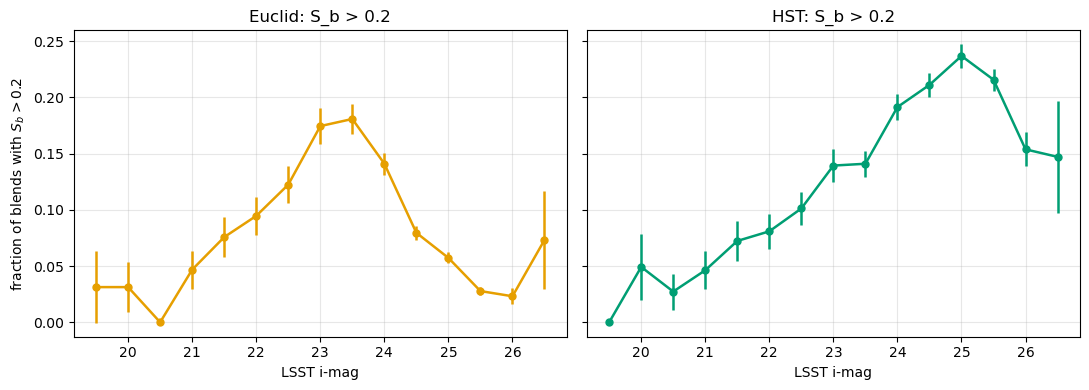

In [9]:
res = plots.Results(case)
lsst = res.lsst
print(f'{len(lsst):,} LSST objects; NaN in the entropy columns:',
      int(lsst[['blending_entropy_Euclid', 'blending_entropy_HST']].isna().sum().sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, tel in zip(ax, ['Euclid', 'HST']):
    x, f, e, n = plots.sb_curve(res, tel, thr=0.2)
    a.errorbar(x, f, yerr=e, marker='o', ms=5, lw=1.8, color=plots.COLORS[tel])
    a.set_title(f'{tel}: S_b > 0.2')
    a.set_xlabel('LSST i-mag'); a.grid(alpha=.3)
ax[0].set_ylabel('fraction of blends with $S_b > 0.2$')
plt.tight_layout(); plt.show()

In [10]:
# how the S_b values are distributed (computed / 1-1 / no overlap)
rows = {}
for tel in ['Euclid', 'HST']:
    s = lsst[f'blending_entropy_{tel}']
    rows[tel] = {'S_b = -1 (no overlap)': int((s == -1).sum()), 'S_b = 0 (1-1 groups)': int((s == 0).sum()),
                 'S_b > 0 (computed)': int((s > 0).sum()), 'S_b > 0.2': int((s > 0.2).sum()), 'NaN': int(s.isna().sum())}
pd.DataFrame(rows)

,Euclid,HST
S_b = -1 (no overlap),1297,358
S_b = 0 (1-1 groups),11354,8683
S_b > 0 (computed),1393,5003
S_b > 0.2,1118,2524
NaN,0,0


## 8. Standard plots

`plots` writes the full set of figures for the case (counts of (true, LSST) objects per group, unrecognized-blend fraction vs magnitude, S_b fractions vs magnitude and blendedness, ...).
To compare several cases: `python -m copaings compare cases/a.yaml cases/b.yaml --out my_comparison`.

In [11]:
cli.run_stage(case, 'plots')
sorted(os.listdir(os.path.join(case.out_dir, 'plots')))

saved ./copaings_runs/demo_dp2_box/plots/detect_counts.pdf


saved ./copaings_runs/demo_dp2_box/plots/detect_counts_cbar_on_top.pdf
saved ./copaings_runs/demo_dp2_box/plots/unrec_frac_and_mag.pdf


saved ./copaings_runs/demo_dp2_box/plots/unrec_frac_and_mag_surface_density.pdf
saved ./copaings_runs/demo_dp2_box/plots/high_sb_unrec.pdf


saved ./copaings_runs/demo_dp2_box/plots/blendedness_high_sb_unrec.pdf
saved ./copaings_runs/demo_dp2_box/plots/blendedness_high_sb_unrec_mag23.5.pdf


saved ./copaings_runs/demo_dp2_box/plots/sb_vs_blendedness_hist.pdf
saved ./copaings_runs/demo_dp2_box/plots/sb_euclid_vs_hst.pdf


['blendedness_high_sb_unrec.pdf',
 'blendedness_high_sb_unrec_mag23.5.pdf',
 'detect_counts.pdf',
 'detect_counts_cbar_on_top.pdf',
 'high_sb_unrec.pdf',
 'sb_euclid_vs_hst.pdf',
 'sb_vs_blendedness_hist.pdf',
 'unrec_frac_and_mag.pdf',
 'unrec_frac_and_mag_surface_density.pdf']

## 9. The same on slurm

For a real case (many tracts) each stage is a slurm job; `submit` writes the sbatch scripts and chains them with `--dependency=afterok`
(prep → fof → eot array → merge → magfit → sb array → sb_merge → plots). `--dry-run` only writes the scripts and prints the commands.
Useful options: `--from-stage magfit` (earlier stages are assumed done), `--skip-stages fof,eot,eot_merge`, `--after <jobid,...>`.
Set `setup_cmd`, `account`, `partition`, `mem` in the case file first.

In [12]:
from copaings import submit
from dataclasses import replace
slurm_case = replace(case, setup_cmd='source /path/to/loadLSST.bash && setup lsst_distrib', account='your:account')
submit.submit(slurm_case, dry_run=True)       # CLI:  python -m copaings submit cases/<case>.yaml [--dry-run]

DRY sbatch --parsable ./copaings_runs/demo_dp2_box/slurm/prep.sbatch
DRY sbatch --parsable --dependency=afterok:DRY1 ./copaings_runs/demo_dp2_box/slurm/fof_E.sbatch
DRY sbatch --parsable --dependency=afterok:DRY2 ./copaings_runs/demo_dp2_box/slurm/eot_E.sbatch
DRY sbatch --parsable --dependency=afterok:DRY3 ./copaings_runs/demo_dp2_box/slurm/eotmerge_E.sbatch
DRY sbatch --parsable --dependency=afterok:DRY1 ./copaings_runs/demo_dp2_box/slurm/fof_H.sbatch
DRY sbatch --parsable --dependency=afterok:DRY5 ./copaings_runs/demo_dp2_box/slurm/eot_H.sbatch
DRY sbatch --parsable --dependency=afterok:DRY6 ./copaings_runs/demo_dp2_box/slurm/eotmerge_H.sbatch
DRY sbatch --parsable --dependency=afterok:DRY1:DRY4:DRY7 ./copaings_runs/demo_dp2_box/slurm/magfit.sbatch
DRY sbatch --parsable --dependency=afterok:DRY8 ./copaings_runs/demo_dp2_box/slurm/sb_E.sbatch
DRY sbatch --parsable --dependency=afterok:DRY8 ./copaings_runs/demo_dp2_box/slurm/sb_H.sbatch
DRY sbatch --parsable --dependency=afterok:DRY9: